# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import missingno as msno  
import plotly.express as px 

# Reading Data Set

In [2]:
df = pd.read_csv("clinical_assessment.csv")
df.head(1)

,Patient_ID,Clinical_Log_Raw,Resource_Allocated_USD,Severity_Score,Treatment_Success
0,3654,LOG:DRG-37_STAT-634,5514.57,6.8,1


# Data Understanding & Quality

In [3]:
print(df.shape)

(10200, 5)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10200 entries, 0 to 10199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              10200 non-null  int64  
 1   Clinical_Log_Raw        9898 non-null   str    
 2   Resource_Allocated_USD  9691 non-null   float64
 3   Severity_Score          9897 non-null   float64
 4   Treatment_Success       10200 non-null  int64  
dtypes: float64(2), int64(2), str(1)
memory usage: 398.6 KB


<Axes: >

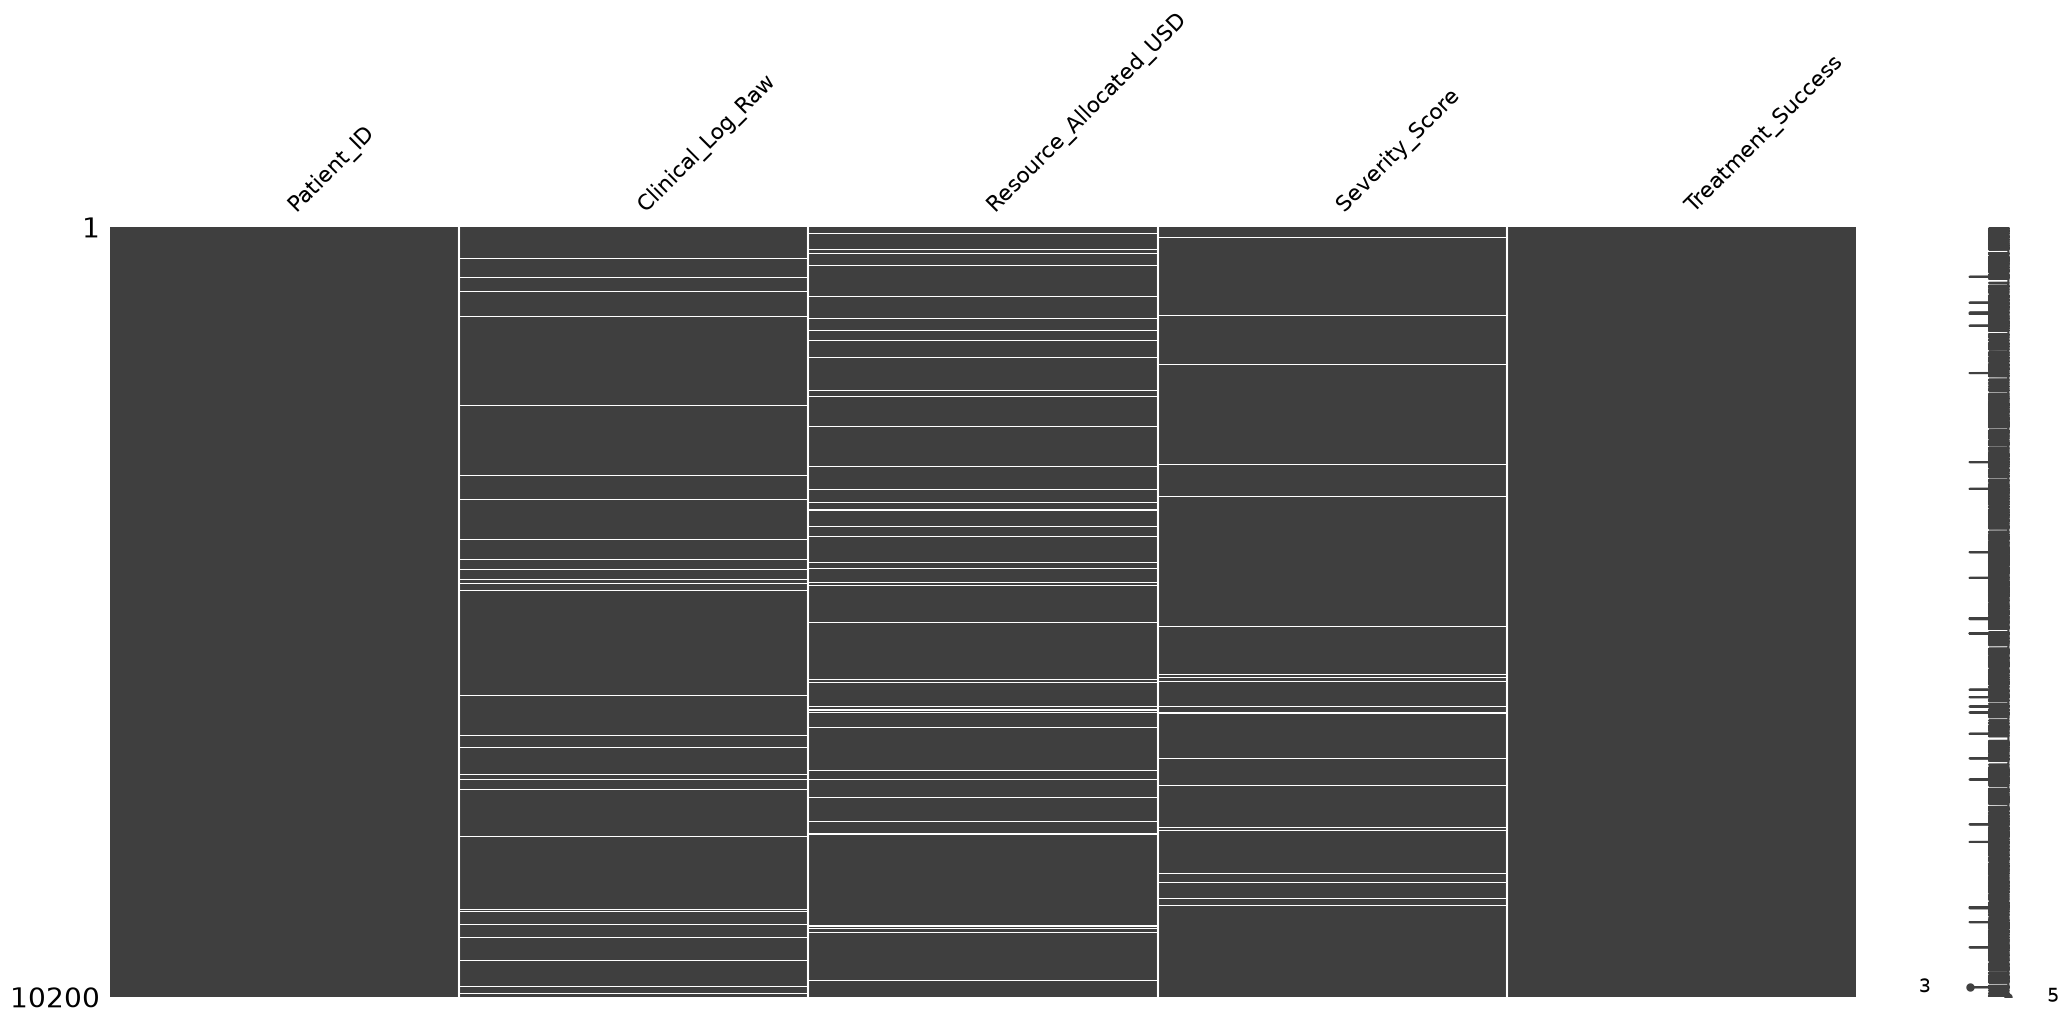

In [5]:
msno.matrix(df)  

In [6]:
# fill out null values with mean 
df["Severity_Score"] = df["Severity_Score"].fillna(df["Severity_Score"].mean())
df["Resource_Allocated_USD"] = df["Resource_Allocated_USD"].fillna(df["Resource_Allocated_USD"].mean())

In [7]:
# fill out null values with mode
mode_value = df["Clinical_Log_Raw"].mode()[0]  
df["Clinical_Log_Raw"] = df["Clinical_Log_Raw"].fillna(mode_value)

<Axes: >

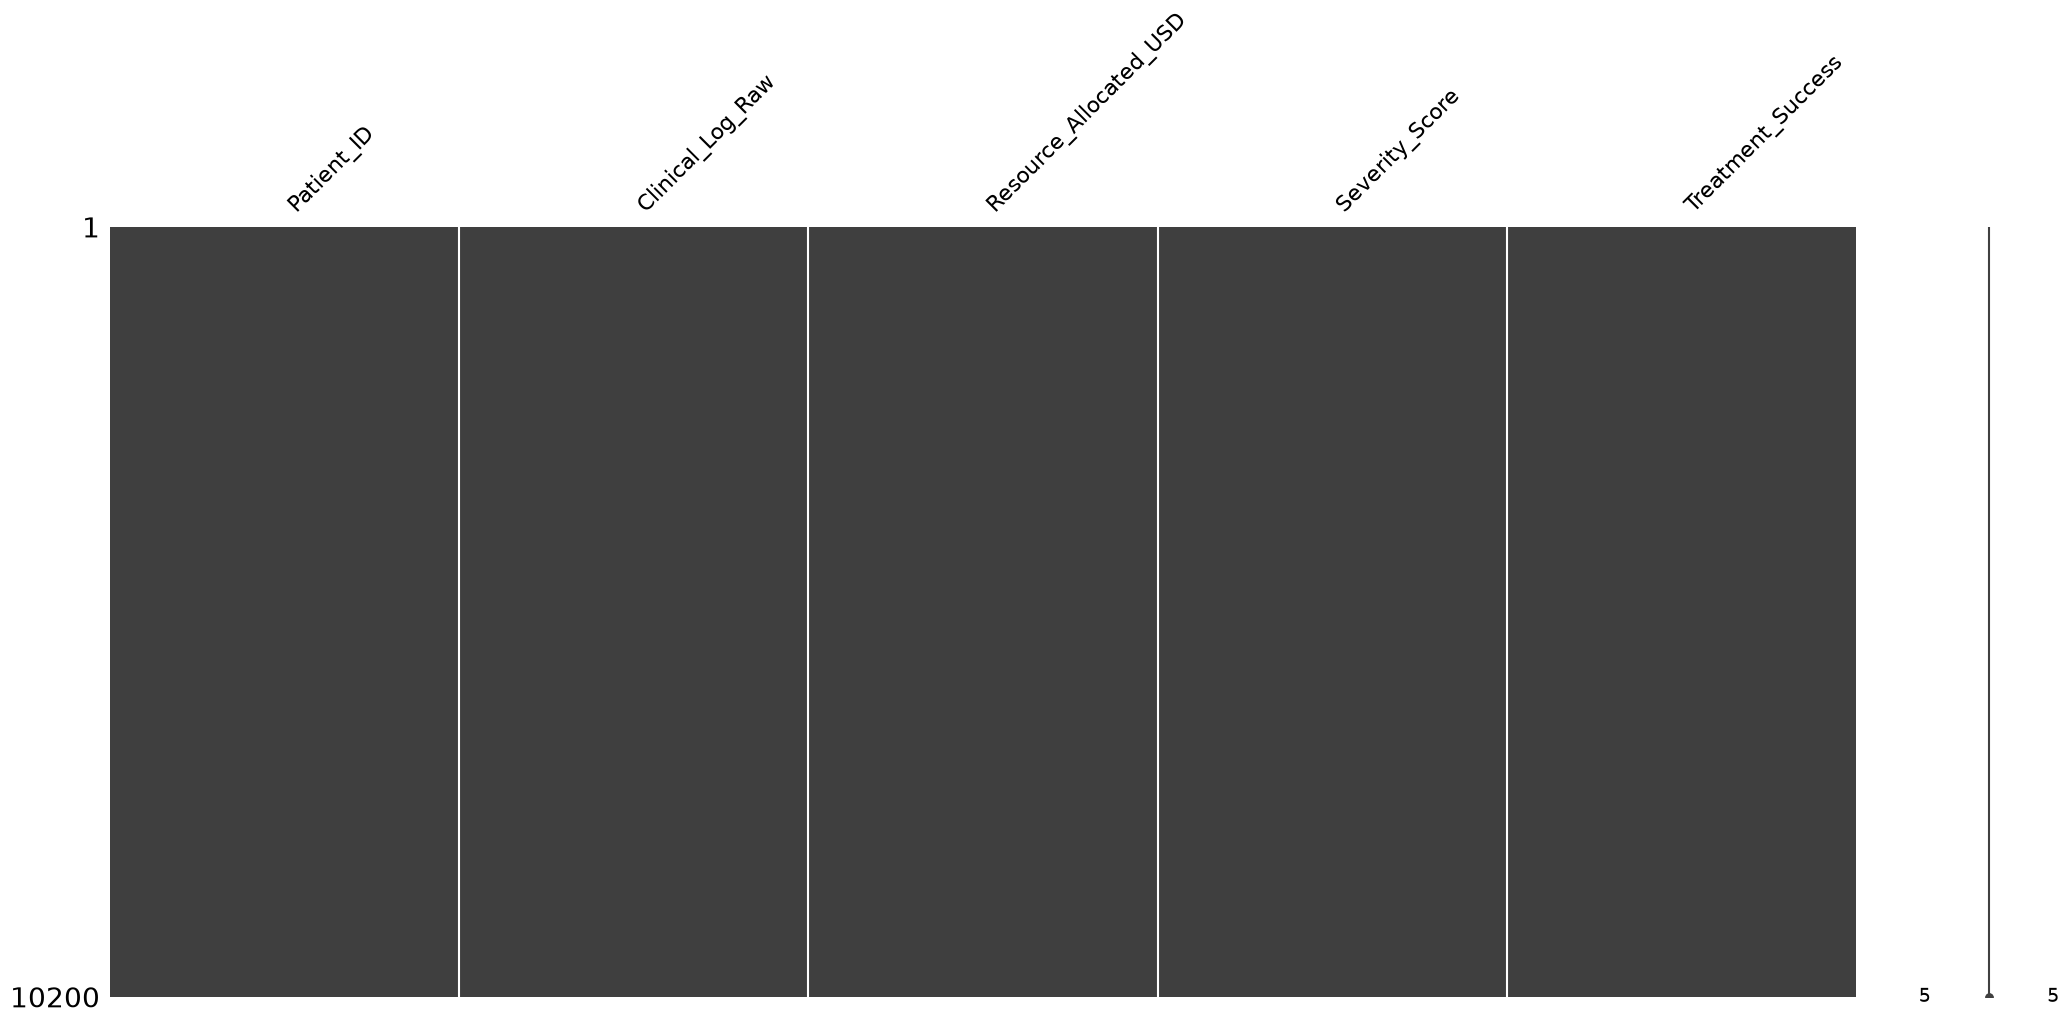

In [8]:
msno.matrix(df)  

In [9]:
# count and percent of missing values of each column
missing = pd.DataFrame({"Missing_Count" : df.isnull().sum(),"Missing_Percent":df.isnull().mean()*100
                        })
display(missing.round(2))

,Missing_Count,Missing_Percent
Patient_ID,0,0.0
Clinical_Log_Raw,0,0.0
Resource_Allocated_USD,0,0.0
Severity_Score,0,0.0
Treatment_Success,0,0.0


In [10]:
# duplicates of whole Dataframe  ~ duplicated rows
print("Full Duplicates:", df.duplicated().sum())    # repeated records (it is about whole row)
# duplicates of patient_ID column
print("Patient ID Duplicates:",
      df.duplicated(subset=['Patient_ID']).sum())    # it is OK maybe we have a patient, who received multiple treatments.

Full Duplicates: 200
Patient ID Duplicates: 7310


## drop exact (Full) duplicates

In [11]:
df = df.drop_duplicates()

print("Remaining Full Duplicates:", df.duplicated().sum())
print("New Shape:", df.shape)

Remaining Full Duplicates: 0
New Shape: (10000, 5)


In [12]:
# succes & unsuccess rate for treatment ---> 1 means treated/ 0 means not
df["Treatment_Success"].value_counts (dropna = False)

Treatment_Success
1    6526
0    3474
Name: count, dtype: int64

In [13]:
print("unique patients:" , df["Patient_ID"].nunique())
print("Repeated Patients:" , (df["Patient_ID"].value_counts()>1).sum())
print("Invalid Severity:" , ((df["Severity_Score"]<1)|(df["Severity_Score"]>10)).sum())   #in the intro stated that Severity is between 1-10

print("Success Values:", df["Treatment_Success"].unique())
print("Exact Duplicates:",df.duplicated().sum())   

unique patients: 2890
Repeated Patients: 2546
Invalid Severity: 40
Success Values: [1 0]
Exact Duplicates: 0


In [14]:
(round(df.loc[df["Severity_Score"] > 10, "Severity_Score"].describe(),2)).to_frame().T       # abnormal patients 

,count,mean,std,min,25%,50%,75%,max
Severity_Score,40.0,20.44,2.81,15.04,18.41,20.56,22.65,24.9


In [15]:
df.loc[                                          # observing abnormal severity values 
    df["Severity_Score"] > 10, ["Patient_ID","Severity_Score","Resource_Allocated_USD","Treatment_Success"]].head(3)  

,Patient_ID,Severity_Score,Resource_Allocated_USD,Treatment_Success
883,1125,15.204851,4559.570000,1
1313,2441,23.099754,5152.980281,1
1490,2854,17.285998,4529.540000,1


In [16]:
# abnormal values for severity score  out of the range [1-10]
# making a new column of it bcs it is useful in the future for us
df["Severity_Invalid"] = (
    (df["Severity_Score"]<1) | (df["Severity_Score"]>10)    # based on True or False / False means in range of 1-10
)
df["Severity_Invalid"].value_counts()           # we have 40 abnormalities

Severity_Invalid
False    9960
True       40
Name: count, dtype: int64

In [17]:
#unique patients between these 40 abnormality (just 1 duplicated between these 40 abnormal patients)
df.loc[
    df["Severity_Invalid"], "Patient_ID"
].nunique()   

39

In [18]:
df["Severity_Flag"] = "Normal"           # initiallzing Normal & check to the coresponding rows (patients)
df.loc[
    (df["Severity_Score"]<1) | (df["Severity_Score"]>10), 
    "Severity_Flag" 
] = "Check"

In [19]:
df["Severity_Flag"].value_counts()      # we have 40 checks, which means, 40 abnormalities out of the range 1-10

Severity_Flag
Normal    9960
Check       40
Name: count, dtype: int64

In [20]:
df.head(1)                    # new columns help us for further precise result and observe suspicious records!

,Patient_ID,Clinical_Log_Raw,Resource_Allocated_USD,Severity_Score,Treatment_Success,Severity_Invalid,Severity_Flag
0,3654,LOG:DRG-37_STAT-634,5514.57,6.8,1,False,Normal


In [21]:
df.loc[
    df["Severity_Flag"] == "Check"           # observing just most frequent patients, who are abnormal!
].groupby("Patient_ID").size().sort_values(
    ascending = False
).head(5)  

Patient_ID
3791    2
1125    1
1091    1
1255    1
1374    1
dtype: int64

# Feature Engineering

### extracting DRG & STAT from Clinical_Log_Raw column

In [22]:
df[['DRG', 'STAT']] = df['Clinical_Log_Raw'].str.extract(
    r'(?i)DRG-(\d+)\s*_?\s*STAT-(\d+)'
)

In [23]:
#df[["DRG","STAT"]] = df["Clinical_Log_Raw"].str.extract(
#    r'DRG-(\d+)_STAT-(\d+)' 
#)

In [24]:
# just checking above extracting
df[["Clinical_Log_Raw","DRG","STAT"]].head(3)        # Done! it works!!!

,Clinical_Log_Raw,DRG,STAT
0,LOG:DRG-37_STAT-634,37,634
1,LOG:DRG-18_STAT-510,18,510
2,LOG:DRG-66_STAT-855,66,855


<Axes: >

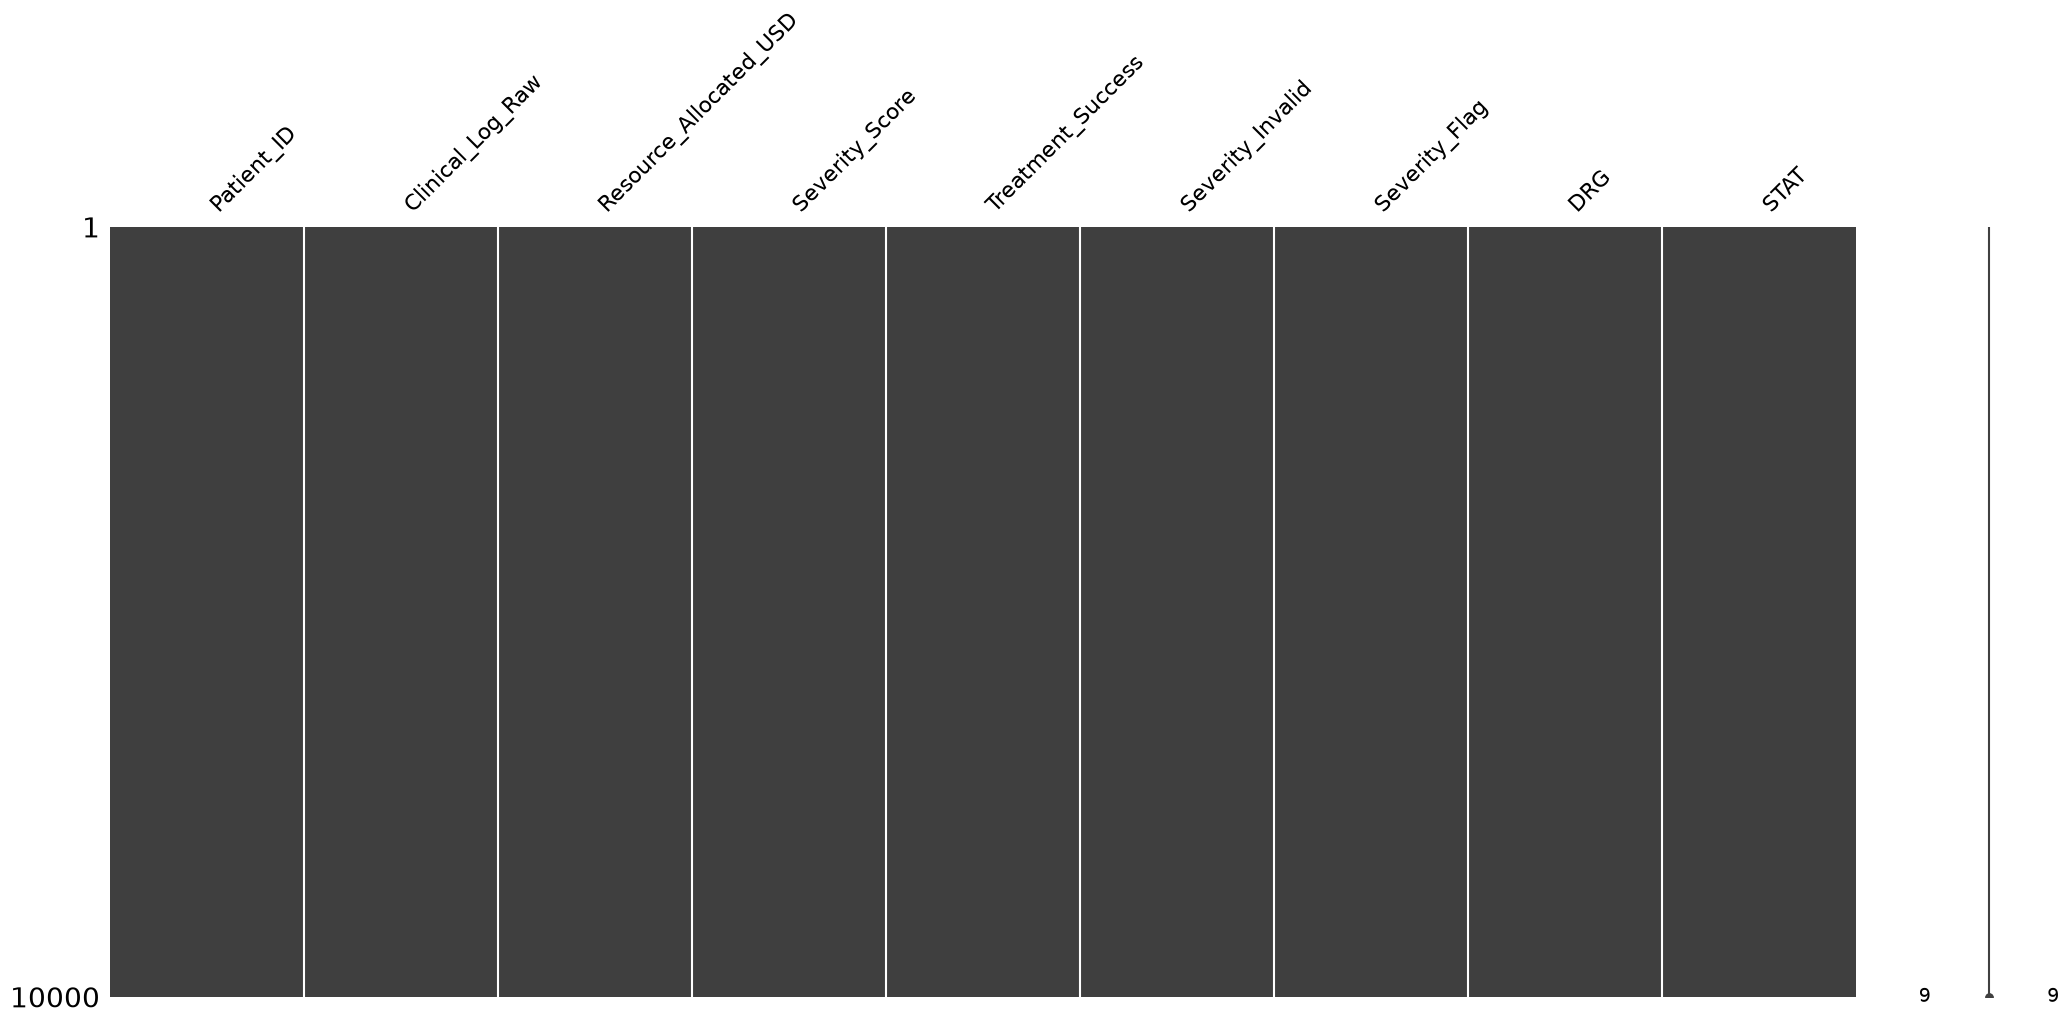

In [25]:
msno.matrix(df)  

In [26]:
df[["DRG","STAT"]].isnull().sum()                            # how many of this extraction failed?

DRG     0
STAT    0
dtype: int64

In [27]:
print(df[['Clinical_Log_Raw', 'DRG', 'STAT']].sample(10))   # being sure that extraction is reliable

         Clinical_Log_Raw DRG STAT
6893  LOG:DRG-36_STAT-684  36  684
5104  LOG:DRG-72_STAT-215  72  215
5105  LOG:DRG-79_STAT-529  79  529
9914  LOG:DRG-94_STAT-844  94  844
3917  LOG:DRG-25_STAT-416  25  416
9177  LOG:DRG-35_STAT-350  35  350
8695  LOG:DRG-32_STAT-891  32  891
3898  LOG:DRG-32_STAT-756  32  756
8765  LOG:DRG-31_STAT-312  31  312
4952  LOG:DRG-82_STAT-159  82  159


In [28]:
#null values in main column
print("Original Null:",
      df['Clinical_Log_Raw'].isnull().sum())

# null values bcs of bad extraction
print("Extraction Failed:",
      df.loc[
          df['Clinical_Log_Raw'].notnull(),
          'DRG'
      ].isnull().sum())

Original Null: 0
Extraction Failed: 0


In [29]:
print("Unique DRG:",
      df['DRG'].nunique())

print("Unique STAT:",
      df['STAT'].nunique())

Unique DRG: 90
Unique STAT: 900


# EDA & Data Quality

In [30]:
numeric_cols = [
    'Resource_Allocated_USD',
    'Severity_Score'
]

display(df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Resource_Allocated_USD,10000.0,5154.464563,3528.158284,-988.430572,4221.1775,5059.05,5759.84,79840.541129
Severity_Score,10000.0,7.380185,2.194341,1.000000,6.0000,7.40,9.10,24.900950


In [31]:
success_count = df["Treatment_Success"].value_counts()
success_percent =  (df["Treatment_Success"].value_counts(normalize = True)*100)
dff = pd.DataFrame({
    "Count":success_count, "Percentage" : success_percent
})
dff

# display(pd.DataFrame({
#     "Count":success_count, "Percentage" : success_percent
# }))

,Count,Percentage
Treatment_Success,,
1,6526,65.26
0,3474,34.74


In [32]:
df.head(1)

,Patient_ID,Clinical_Log_Raw,Resource_Allocated_USD,Severity_Score,Treatment_Success,Severity_Invalid,Severity_Flag,DRG,STAT
0,3654,LOG:DRG-37_STAT-634,5514.57,6.8,1,False,Normal,37,634


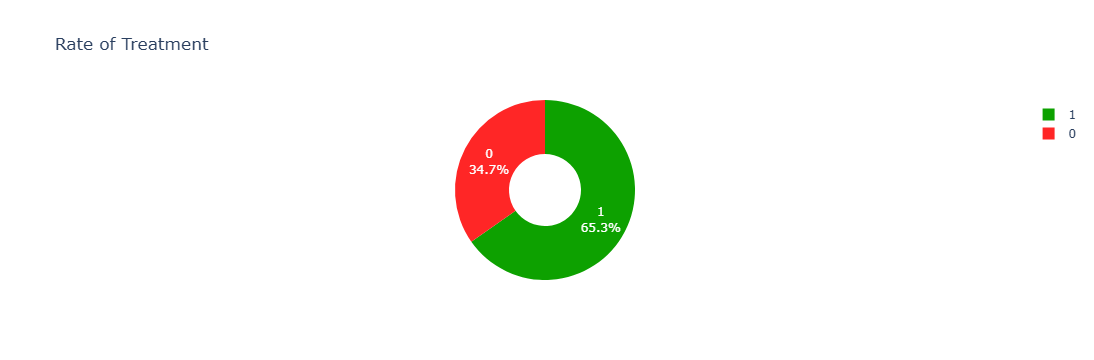

In [33]:
counts = df['Treatment_Success'].value_counts()

fig = px.pie (names = counts.index, values = counts.values,
                title = 'Rate of Treatment', hole = 0.4 , color_discrete_sequence = ["#0DA100", "#FF2626"]
)
fig.update_traces(  textinfo = 'percent+label', textposition = 'inside'
)
fig.show()

In [34]:
df.loc[
    df['Severity_Score'] > 10,
    ['Patient_ID',
     'Severity_Score',
     'Resource_Allocated_USD',
     'Treatment_Success']
].head(5)

,Patient_ID,Severity_Score,Resource_Allocated_USD,Treatment_Success
883,1125,15.204851,4559.570000,1
1313,2441,23.099754,5152.980281,1
1490,2854,17.285998,4529.540000,1
1650,3341,23.142790,5470.040000,1
2148,2960,17.547817,3531.510000,1


In [35]:
round(df['Severity_Score'],2).value_counts().sort_index().to_frame()        # number of different severities

,count
Severity_Score,
1.00,22
1.10,5
1.20,8
1.30,6
1.40,5
...,...
24.13,1
24.49,1
24.62,1


In [36]:
df.head(2)

,Patient_ID,Clinical_Log_Raw,Resource_Allocated_USD,Severity_Score,Treatment_Success,Severity_Invalid,Severity_Flag,DRG,STAT
0,3654,LOG:DRG-37_STAT-634,5514.57,6.8,1,False,Normal,37,634
1,2015,LOG:DRG-18_STAT-510,5541.16,7.1,1,False,Normal,18,510


In [37]:
df.loc[
    df['Severity_Invalid'],
    'Severity_Score'
].sort_values().to_frame().head(5)              # sort ascending abnormal values for severity score 

,Severity_Score
6682,15.043363
883,15.204851
4536,15.545614
7369,16.676526
6677,17.164704


#  Cost Histogram 

In [38]:
df = df.loc[ (df["Resource_Allocated_USD"]>=0) & (df["Resource_Allocated_USD"] <= 20000)  ].copy()
#print((df["Resource_Allocated_USD"] <= 20000) | (df["Resource_Allocated_USD"]>=0).shape[0])
df.shape

(9920, 9)

In [44]:
df["Resource_Allocated_USD"].describe().to_frame().T

,count,mean,std,min,25%,50%,75%,max
Resource_Allocated_USD,9920.0,5002.794351,1180.363815,293.12,4234.5625,5064.77,5755.8,9234.87


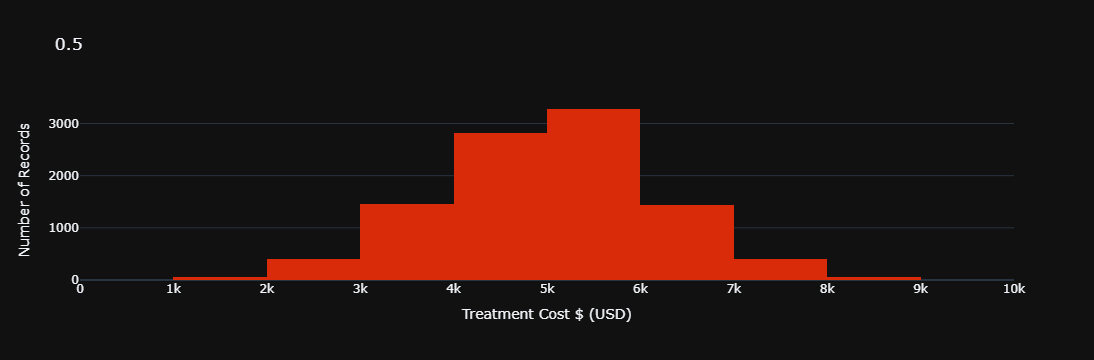

In [47]:
fig = px.histogram (
    df, x = "Resource_Allocated_USD", nbins = 10, title = "Distribution of treatment costs $ ",
    labels = {"Resource_Allocated_USD":"Treatment Cost $ (USD)","count":"Number of Records"}, 
    color_discrete_sequence = ["#D92A09"]
)
fig.update_layout(
    template = "plotly_dark", title = 0.5, xaxis_title = "Treatment Cost $ (USD)", yaxis_title = "Number of Records"
)
fig.show()
                      # almost all the costs are between 0-10k              / big & small values are probably outliers

# Severity Histogram

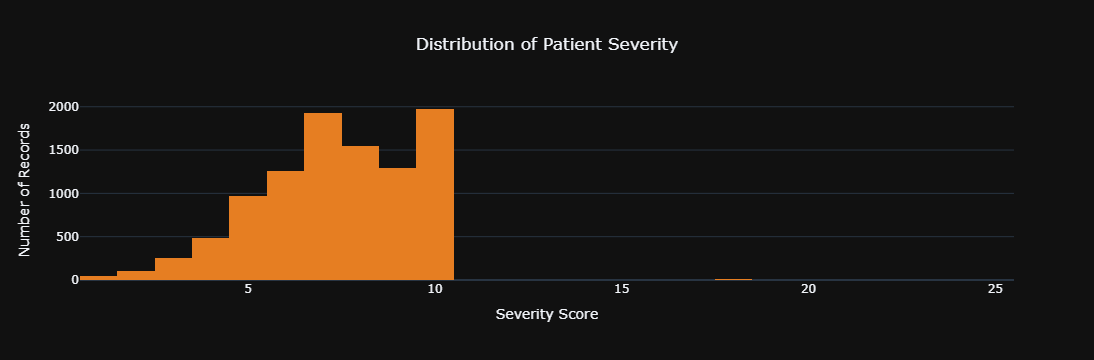

In [48]:
fig = px.histogram(
    df, x = 'Severity_Score', nbins = 30, title = 'Distribution of Patient Severity', color_discrete_sequence = ['#E67E22']
)

fig.update_layout( template = 'plotly_dark', title_x = 0.5, xaxis_title = 'Severity Score', yaxis_title = 'Number of Records')

fig.show()
                                 # cholesky to the right because almost all the severities are between 5-10
                                      # big or out of the range (1-10) values are same abnormalities

In [ ]:
import plotly.io as pio
print(pio.templates)

# relation between Severity & Cost

In [49]:
df.head(1)                                  # just for checking and having the columns in reach

,Patient_ID,Clinical_Log_Raw,Resource_Allocated_USD,Severity_Score,Treatment_Success,Severity_Invalid,Severity_Flag,DRG,STAT
0,3654,LOG:DRG-37_STAT-634,5514.57,6.8,1,False,Normal,37,634


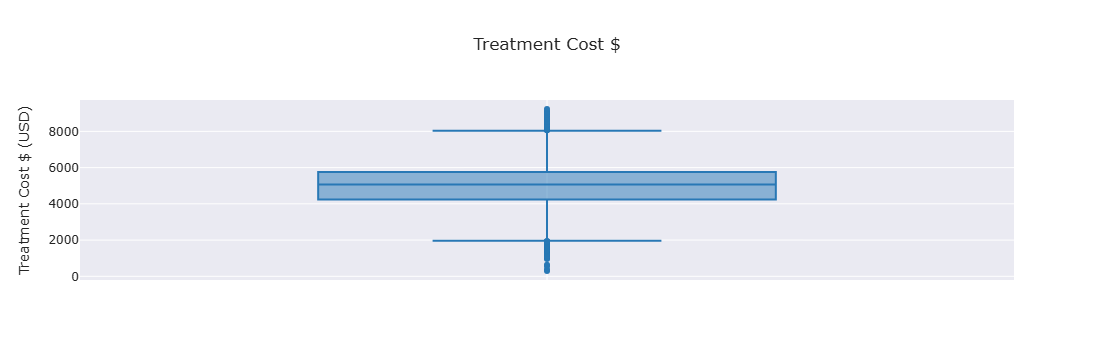

In [50]:
fig = px.box(
    df, y = 'Resource_Allocated_USD', title = 'Treatment Cost $',
    points = 'outliers', color_discrete_sequence = ['#2878B5']
)

fig.update_layout(
    template = 'seaborn',
    title_x = 0.5,
    yaxis_title = 'Treatment Cost $ (USD)'
)

fig.show()

# Bivariate Analysis

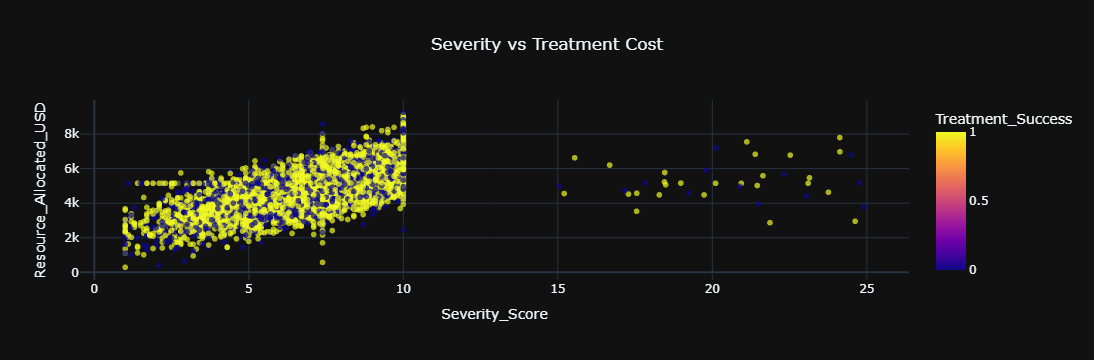

In [51]:
# scatter plot for severity vs cost
# we observe that by increasing severity, cost tends to increase 
fig = px.scatter(
    df, x = "Severity_Score", y = "Resource_Allocated_USD", color = "Treatment_Success", title = "Severity vs Treatment Cost",
    color_discrete_map = {
        0 : "#E3051A", 1 : "#09E35D"
    }, opacity = 0.7
)
fig.update_layout(
    template = "plotly_dark" , title_x = 0.5
)
fig.show()

# Cost in Success & Unsuccess Treatment

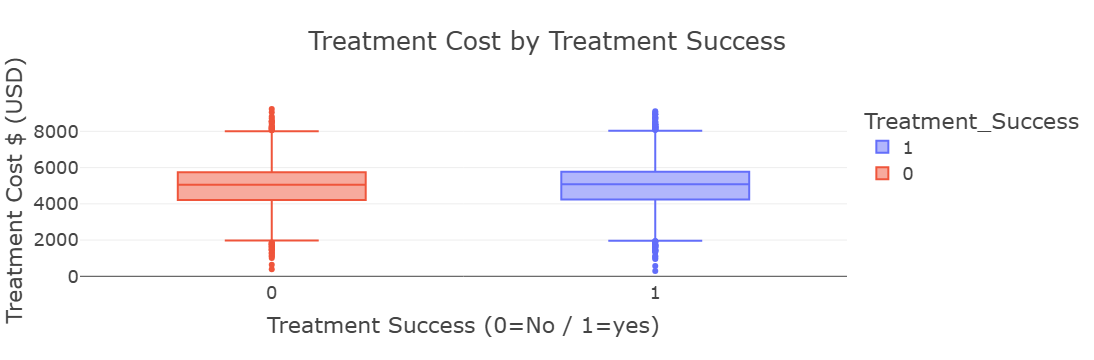

In [52]:
fig = px.box(
    df, x = "Treatment_Success", y = "Resource_Allocated_USD", color = "Treatment_Success", title = "Treatment Cost by Treatment Success"
)
fig.update_layout(
    template = "presentation", title_x = 0.5, xaxis_title = "Treatment Success (0=No / 1=yes)", yaxis_title = "Treatment Cost $ (USD)"
) 
fig.show() 
# almost no difference for cost in success/unsuccess treatment 

# Correlation between Severity & Cost

In [53]:
corr_df = df[["Severity_Score","Resource_Allocated_USD"]].dropna()
print("Pearson:",
      corr_df.corr(method = "pearson").iloc[0,1])
print("Spearman:",
      corr_df.corr(method = "spearman").iloc[0,1])
# pearson cosiders linear relation
# spearman consider unit Distribution
# we observe that spearman is bigger!
# pearson shows that there is no special linear relation between Severity and Cost
# spearman shows that cost tends to increase by increasing severity bcs of its value which is 0.739.... 

Pearson: 0.6708833773051406
Spearman: 0.7170155471451592


In [54]:
# probably the relation between cost and severity is non-linear !!
# spearmann shows that by increasing severity, cost likes to increase (linearly)

In [55]:
severity_cost = df.dropna(
    subset = ['Severity_Score', 'Resource_Allocated_USD']
).copy()

severity_cost['Severity_Group'] = pd.cut(
    severity_cost['Severity_Score'],
    bins = [0, 2, 4, 6, 8, 10, float('inf')],
    labels = [
        '1-2', '2-4', '4-6',
        '6-8', '8-10', 'Above 10'
    ]
)

summary = severity_cost.groupby(
    'Severity_Group',
    observed = True
).agg(
    Record_Count = ('Resource_Allocated_USD', 'count'),
    Mean_Cost = ('Resource_Allocated_USD', 'mean'),
    Median_Cost = ('Resource_Allocated_USD', 'median')
).reset_index()

display(summary.round(2))
# by increasing severity group cost in general will be increased 

,Severity_Group,Record_Count,Mean_Cost,Median_Cost
0,1-2,94,2727.04,2625.56
1,2-4,569,3416.84,3360.56
2,4-6,1959,4124.78,4133.96
3,6-8,3391,4861.18,4896.54
4,8-10,3868,5857.54,5802.38
5,Above 10,39,5269.47,5152.98


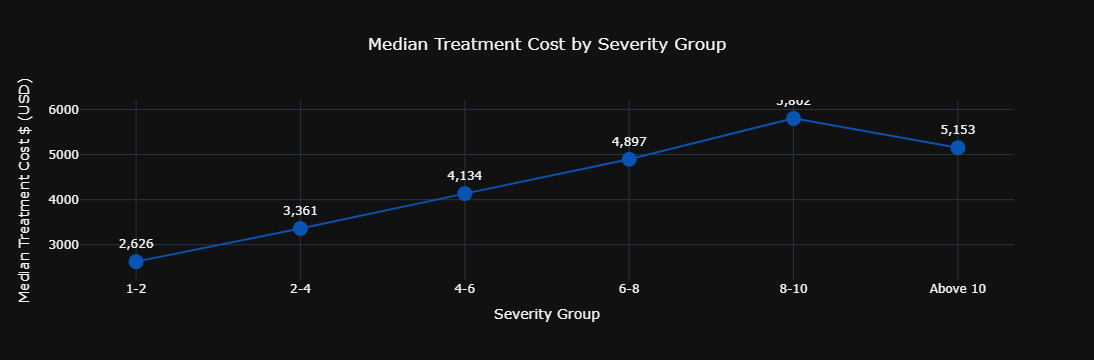

In [56]:
fig = px.line(
    summary, x = 'Severity_Group', y = 'Median_Cost', markers = True, title = 'Median Treatment Cost by Severity Group',
    text = 'Median_Cost'
)

fig.update_traces(
    line = dict(color = '#0953B3', width = 2) ,
    texttemplate = '%{text:,.0f}', marker = dict (size = 15 ) ,
    textposition = 'top center'
)

fig.update_layout(
    template = 'plotly_dark', title_x = 0.5,
    xaxis_title = 'Severity Group', yaxis_title = 'Median Treatment Cost $ (USD)'
)

fig.show()

In [57]:
from scipy.stats import pearsonr, spearmanr

data = df[
    ['Severity_Score', 'Resource_Allocated_USD']
].dropna()

p = pearsonr(
    data['Severity_Score'],
    data['Resource_Allocated_USD']
)

s = spearmanr(
    data['Severity_Score'],
    data['Resource_Allocated_USD']
)

print('Sample Size:', len(data))
print('Pearson:', round(p.statistic,4))
print('Pearson P-value:', p.pvalue)
print('Spearman:', round(s.statistic,4))
print('Spearman P-value:', s.pvalue)

Sample Size: 9920
Pearson: 0.6709
Pearson P-value: 0.0
Spearman: 0.717
Spearman P-value: 0.0


In [58]:
display(summary.round(2))

,Severity_Group,Record_Count,Mean_Cost,Median_Cost
0,1-2,94,2727.04,2625.56
1,2-4,569,3416.84,3360.56
2,4-6,1959,4124.78,4133.96
3,6-8,3391,4861.18,4896.54
4,8-10,3868,5857.54,5802.38
5,Above 10,39,5269.47,5152.98


In [ ]:
# by increasing Severity , cost will be increased 

# Severity & Cost

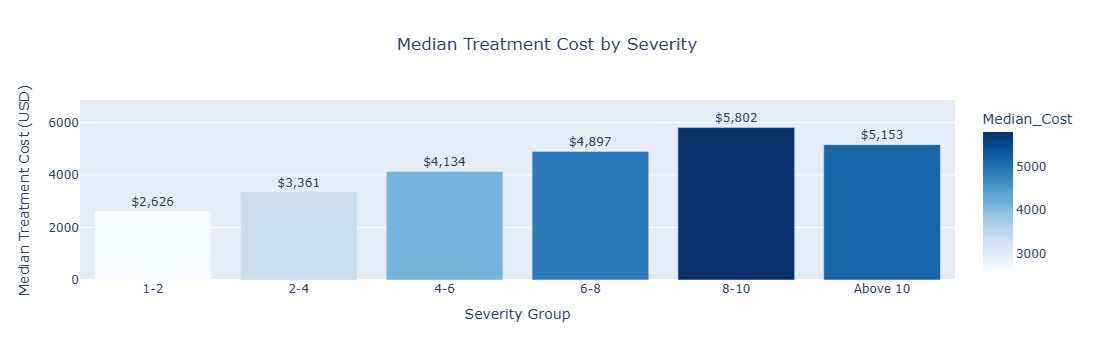

In [59]:
fig = px.bar(
    summary,
    x ='Severity_Group', y ='Median_Cost', text ='Median_Cost', title = 'Median Treatment Cost by Severity',
    color ='Median_Cost', color_continuous_scale = 'Blues'
)

fig.update_traces(
    texttemplate ='$%{text:,.0f}',
    textposition ='outside'
)

fig.update_layout(template = 'plotly', title_x = 0.5, xaxis_title = 'Severity Group', yaxis_title = 'Median Treatment Cost (USD)',
    showlegend = False
)

fig.show()
# the max cost value is in group 8-10 severity

# Severity & Success

In [60]:
success_analysis = df.dropna(
    subset = ['Severity_Score', 'Treatment_Success']
).copy()

success_analysis['Severity_Group'] = pd.cut(
    success_analysis['Severity_Score'],
    bins = [0, 2, 4, 6, 8, 10, float('inf')],
    labels = [
        '1-2', '2-4', '4-6',
        '6-8', '8-10', 'Above 10'
    ]
)

result = success_analysis.groupby(
    'Severity_Group',
    observed = True
).agg(
    Total = ('Treatment_Success', 'count'),
    Successful = ('Treatment_Success', 'sum')
).reset_index()

result['Success_Rate'] = (
    result['Successful'] / result['Total'] * 100
)

display(result.round(2))

,Severity_Group,Total,Successful,Success_Rate
0,1-2,94,57,60.64
1,2-4,569,378,66.43
2,4-6,1959,1249,63.76
3,6-8,3391,2219,65.44
4,8-10,3868,2545,65.80
5,Above 10,39,26,66.67


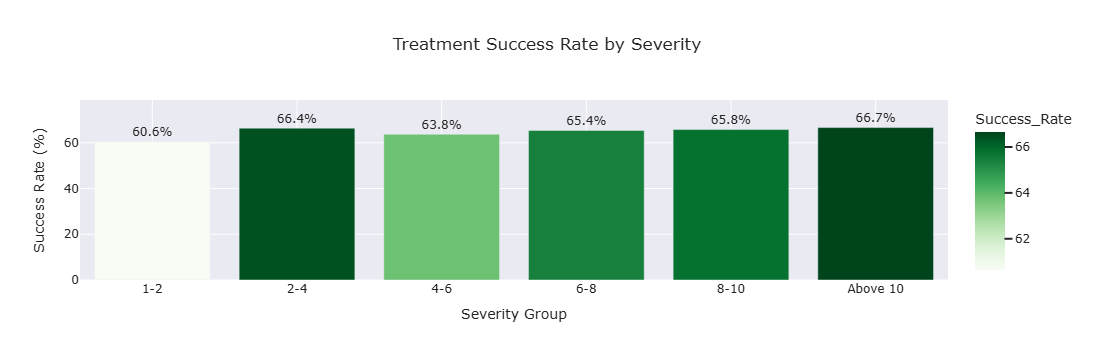

In [61]:
fig = px.bar(
    result,
    x = 'Severity_Group', y = 'Success_Rate',text = 'Success_Rate',
    title = 'Treatment Success Rate by Severity', color = 'Success_Rate', color_continuous_scale = 'Greens'
)

fig.update_traces(
    texttemplate = '%{text:.1f}%',
    textposition = 'outside'
)

fig.update_layout(
    template = 'seaborn',
    title_x = 0.5,
    xaxis_title = 'Severity Group',
    yaxis_title = 'Success Rate (%)'
)

fig.show()
# the most rate of success is in group 2-4 but almost all of them are in almost same rate, yeah?

In [ ]:
# the best recovered group is severity 2-4 & above 10 almost same

# Cost & Success

In [62]:
cost_success = df.dropna(
    subset=['Resource_Allocated_USD', 'Treatment_Success']
).copy()

result_cost = cost_success.groupby('Treatment_Success').agg(
    Patient_Count = ('Patient_ID', 'count'),
    Mean_Cost     = ('Resource_Allocated_USD','mean'),
    Median_Cost   = ('Resource_Allocated_USD','median'),
    Min_Cost      = ('Resource_Allocated_USD','min'),
    Max_Cost      = ('Resource_Allocated_USD','max')
).reset_index()

display(result_cost.round(2))
# mean cost for successful treatment is just a little higher!  
# mean value of cost for both group of recovered & unrecovered is almost same!

,Treatment_Success,Patient_Count,Mean_Cost,Median_Cost,Min_Cost,Max_Cost
0,0,3446,4994.04,5049.50,396.01,9234.87
1,1,6474,5007.45,5074.98,293.12,9114.69


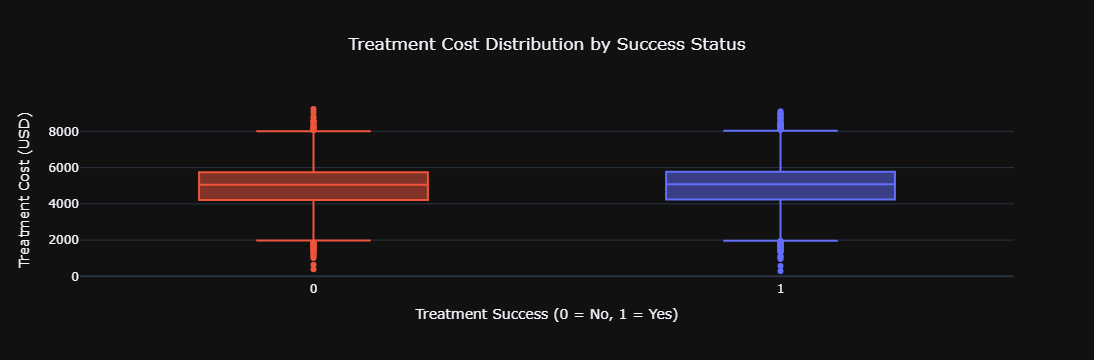

In [63]:
fig = px.box(
    cost_success, x = 'Treatment_Success', y = 'Resource_Allocated_USD',
    color = 'Treatment_Success', title = 'Treatment Cost Distribution by Success Status',
    labels = {
        'Treatment_Success': 'Treatment Success (0 = No, 1 = Yes)',
        'Resource_Allocated_USD': 'Treatment Cost (USD)'
    }
)

fig.update_layout(
    template   = 'plotly_dark',
    title_x    = 0.5,
    showlegend = False
)

fig.show()

In [64]:
#number of negative costs!
negative_cost = df[df['Resource_Allocated_USD'] < 0]

print( "number of negative costs:" , len (negative_cost))

# #number of zero costs!
zero_cost = df[df['Resource_Allocated_USD'] == 0]

print ("number of zero costs:", len (zero_cost))

#summary of costs
display(
    df['Resource_Allocated_USD'].describe().round(2)
)

number of negative costs: 0
number of zero costs: 0


count    9920.00
mean     5002.79
std      1180.36
min       293.12
25%      4234.56
50%      5064.77
75%      5755.80
max      9234.87
Name: Resource_Allocated_USD, dtype: float64

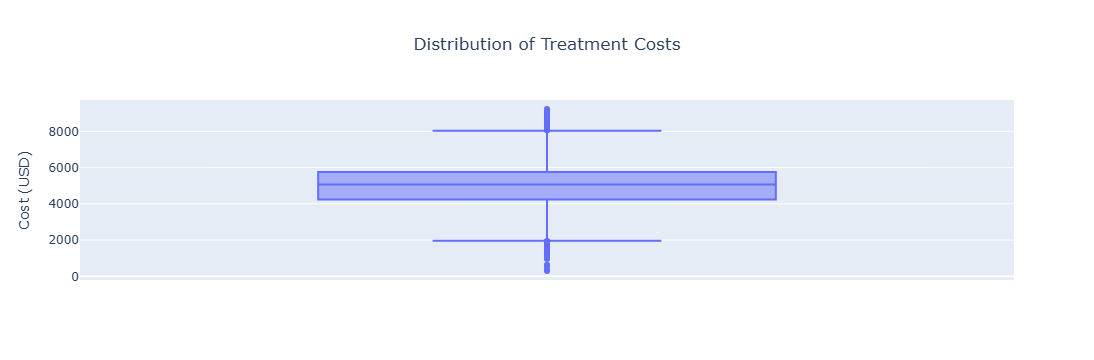

In [65]:
fig = px.box(
    df, y = 'Resource_Allocated_USD', title = 'Distribution of Treatment Costs'
)

fig.update_layout(
    template = 'plotly',
    title_x = 0.5,
    yaxis_title = 'Cost (USD)'
)

fig.show()

In [66]:
negative_cost = df[df['Resource_Allocated_USD'] < 0].copy()
display(
    negative_cost['Treatment_Success'].value_counts() 
) 

Series([], Name: count, dtype: int64)

In [67]:
# calculating lower and upper bound of costs
Q1 = df['Resource_Allocated_USD'].quantile(0.25)
Q3 = df['Resource_Allocated_USD'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Resource_Allocated_USD'] < lower_bound) |
    (df['Resource_Allocated_USD'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", round(lower_bound,4))
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))
print("Percentage:", round(len(outliers) / len(df) * 100, 2), "%")
# it means that cost lower than 1708 and more than 8286 $ can be considered as outlier!

Q1: 4234.5625
Q3: 5755.799999999999
IQR: 1521.2374999999993
Lower Bound: 1952.7063
Upper Bound: 8037.656249999998
Number of Outliers: 114
Percentage: 1.15 %


# Analysis of STAT and DRG

In [68]:
df.head(1)

,Patient_ID,Clinical_Log_Raw,Resource_Allocated_USD,Severity_Score,Treatment_Success,Severity_Invalid,Severity_Flag,DRG,STAT
0,3654,LOG:DRG-37_STAT-634,5514.57,6.8,1,False,Normal,37,634


In [69]:
# making DRG DataFrame
drg_analysis = df.dropna(
    subset = ['DRG', 'Resource_Allocated_USD', 'Treatment_Success']
).copy()

drg_summary      = drg_analysis.groupby('DRG').agg(
    Record_Count = ('DRG', 'size'),
    Mean_Cost    = ('Resource_Allocated_USD', 'mean'),
    Median_Cost  = ('Resource_Allocated_USD', 'median'),
    Success_Rate = ('Treatment_Success', 'mean')
).reset_index()

drg_summary['Success_Rate'] *= 100

#sorting based on number of records
drg_summary = drg_summary.sort_values(
    'Record_Count', ascending = False
)

display(drg_summary.head(5).round(2))
# DRG 94,72,78,98 and 83 are most frequent one!

,DRG,Record_Count,Mean_Cost,Median_Cost,Success_Rate
26,36,400,5048.19,5152.98,65.00
62,72,144,5159.38,5152.98,69.44
84,94,141,5091.29,5140.20,65.96
73,83,128,4852.68,5070.90,66.41
87,97,126,4979.98,5101.43,65.87


In [70]:
drg_filtered = drg_summary[    # we consider just more frequent drg for example more than 30 times
    drg_summary['Record_Count'] >= 30
].copy()

top_cost_drg = drg_filtered.sort_values(
    'Mean_Cost', ascending = False
)

display(top_cost_drg.head(5).round(2))

,DRG,Record_Count,Mean_Cost,Median_Cost,Success_Rate
20,30,104,5240.75,5143.54,50.96
30,40,97,5220.09,5152.98,58.76
13,23,115,5196.83,5152.98,61.74
23,33,90,5186.46,5152.98,63.33
85,95,93,5172.31,5152.98,67.74


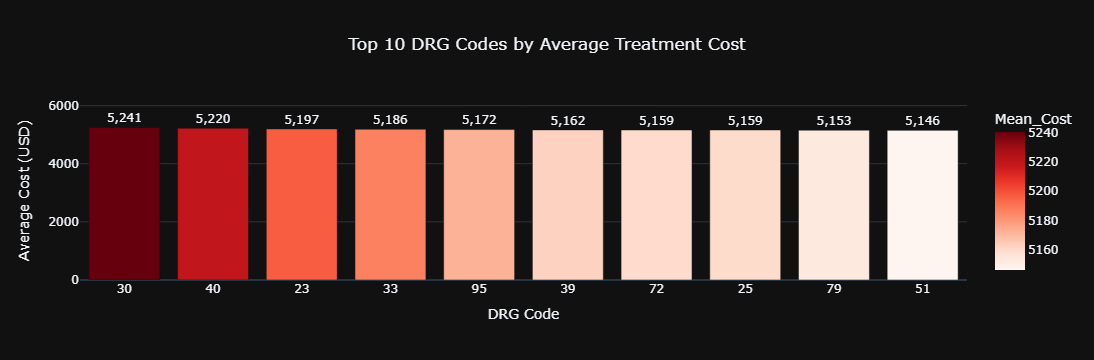

In [71]:
# mean cost of top 10 DRG 
fig = px.bar(
    top_cost_drg.head(10), x = 'DRG', y = 'Mean_Cost', color = 'Mean_Cost',
    text = 'Mean_Cost', title = 'Top 10 DRG Codes by Average Treatment Cost',
    color_continuous_scale = 'Reds'
)

fig.update_traces(
    texttemplate ='%{text:,.0f}',
    textposition ='outside'
)

fig.update_layout(
    template = 'plotly_dark',
    title_x = 0.5, xaxis_title = 'DRG Code', yaxis_title = 'Average Cost (USD)'
)
fig.show()

# Same for STAT

In [72]:
# making STAT DataFrame
stat_analysis = df.dropna(
    subset    = ['STAT', 'Resource_Allocated_USD', 'Treatment_Success']
).copy()

stat_summary     = stat_analysis.groupby('STAT').agg(
    Record_Count = ('STAT', 'size'),
    Mean_Cost    = ('Resource_Allocated_USD', 'mean'),
    Median_Cost  = ('Resource_Allocated_USD', 'median'),
    Success_Rate = ('Treatment_Success', 'mean')
).reset_index()

stat_summary['Success_Rate'] *= 100

stat_summary = stat_summary.sort_values(
    'Record_Count', ascending = False
)
display(stat_summary.head(5).round(2))

,STAT,Record_Count,Mean_Cost,Median_Cost,Success_Rate
584,684,305,5047.15,5128.68,64.26
481,581,21,5637.66,5194.50,76.19
9,109,21,5022.77,5074.62,66.67
781,881,21,4880.26,4753.66,66.67
184,284,21,5167.91,4960.81,57.14


In [73]:
stat_filtered = stat_summary[
    stat_summary['Record_Count'] >= 10
].copy()

top_stat_cost = stat_filtered.sort_values(
    'Mean_Cost',
    ascending = False 
)
display(top_stat_cost.head(5).round(2)) 

,STAT,Record_Count,Mean_Cost,Median_Cost,Success_Rate
191,291,10,5985.82,6015.92,80.00
696,796,13,5965.72,6123.38,69.23
173,273,10,5963.88,6239.66,60.00
710,810,12,5919.11,6045.80,75.00
177,277,11,5872.39,6335.16,45.45


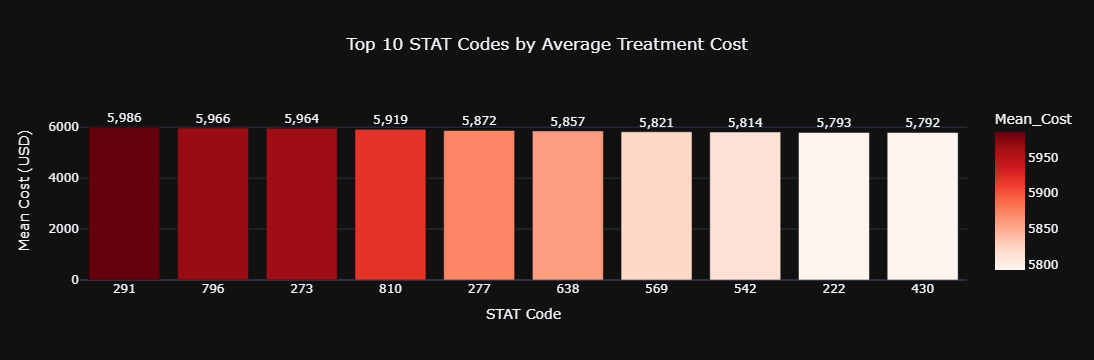

In [74]:
fig = px.bar( 
    top_stat_cost.head(10),
    x = 'STAT', y = 'Mean_Cost', text = 'Mean_Cost',
    color = 'Mean_Cost', color_continuous_scale = 'Reds',
    title = 'Top 10 STAT Codes by Average Treatment Cost'
)

fig.update_traces( texttemplate='%{text:,.0f}', textposition='outside'
)

fig.update_layout(
    template='plotly_dark',
    title_x = 0.5, xaxis_title = 'STAT Code', yaxis_title = 'Mean Cost (USD)'
)

fig.show() 

In [75]:
top_stat_success = stat_filtered.sort_values(
    'Success_Rate',
    ascending = False      # means descending
)

display(top_stat_success.head(5).round(2))   

,STAT,Record_Count,Mean_Cost,Median_Cost,Success_Rate
402,502,10,5260.84,5106.25,100.00
837,937,11,4733.31,4830.00,100.00
618,718,14,4896.85,4552.98,92.86
873,973,14,5079.55,5223.67,92.86
33,133,13,5531.50,5772.95,92.31


In [76]:
from scipy.stats import spearmanr, pearsonr

stat_corr  = stat_filtered.dropna(
    subset = ['Mean_Cost', 'Success_Rate']
)

pearson_result = pearsonr(
    stat_corr['Mean_Cost'],
    stat_corr['Success_Rate']
)

spearman_result = spearmanr(
    stat_corr['Mean_Cost'],
    stat_corr['Success_Rate']
)

print("Number of STAT codes:", len(stat_corr))

print("Pearson Correlation:", round(pearson_result.statistic, 3))
print("Pearson P-value:", round(pearson_result.pvalue, 4))

print("Spearman Correlation:", round(spearman_result.statistic, 3))
print("Spearman P-value:", round(spearman_result.pvalue, 4))

Number of STAT codes: 567
Pearson Correlation: -0.01
Pearson P-value: 0.813
Spearman Correlation: -0.009
Spearman P-value: 0.8253


In [ ]:
# both pearson and spearman values are so weak. it means even linear relation is so weak.
#both p-values are greater than 0.05 so we can not deny or reject null-hypothesis.

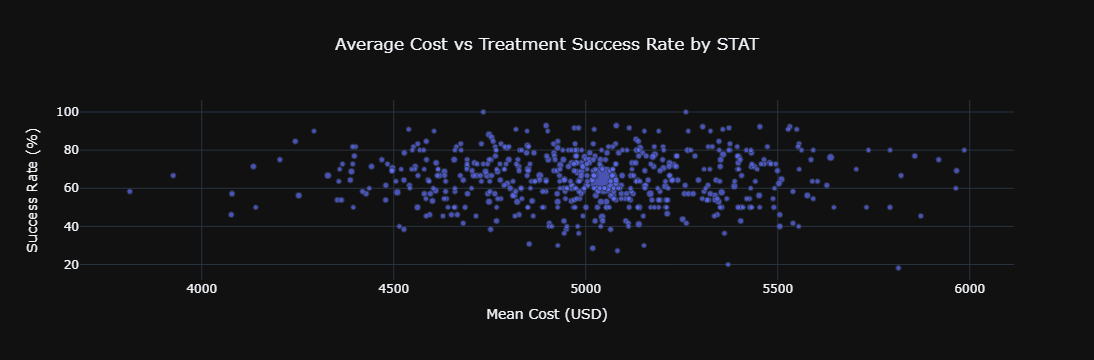

In [77]:
fig = px.scatter(
    stat_corr,
    x = 'Mean_Cost', y ='Success_Rate', size = 'Record_Count',
    hover_name = 'STAT', title = 'Average Cost vs Treatment Success Rate by STAT'
)
fig.update_layout(
    template = 'plotly_dark', title_x = 0.5, xaxis_title = 'Mean Cost (USD)', yaxis_title = 'Success Rate (%)'
)
fig.show()

# DRG

In [78]:
drg_filtered = drg_summary[
    drg_summary['Record_Count'] >= 30
].dropna(
    subset = ['Mean_Cost', 'Success_Rate']
).copy()

print("Number of DRG codes:", len( drg_filtered )) 

Number of DRG codes: 90


In [79]:
from scipy.stats import pearsonr, spearmanr

pearson_result = pearsonr(
    drg_filtered['Mean_Cost'],
    drg_filtered['Success_Rate']
)

spearman_result = spearmanr(
    drg_filtered ['Mean_Cost'],
    drg_filtered ['Success_Rate'] 
)

print("Pearson Correlation:", round(pearson_result.statistic, 3))
print("Pearson P-value:", round(pearson_result.pvalue, 4))

print("Spearman Correlation:", round(spearman_result.statistic, 3))
print("Spearman P-value:", round(spearman_result.pvalue, 4)) 
# still we can not say anything! 

Pearson Correlation: 0.002
Pearson P-value: 0.9886
Spearman Correlation: 0.058
Spearman P-value: 0.5885


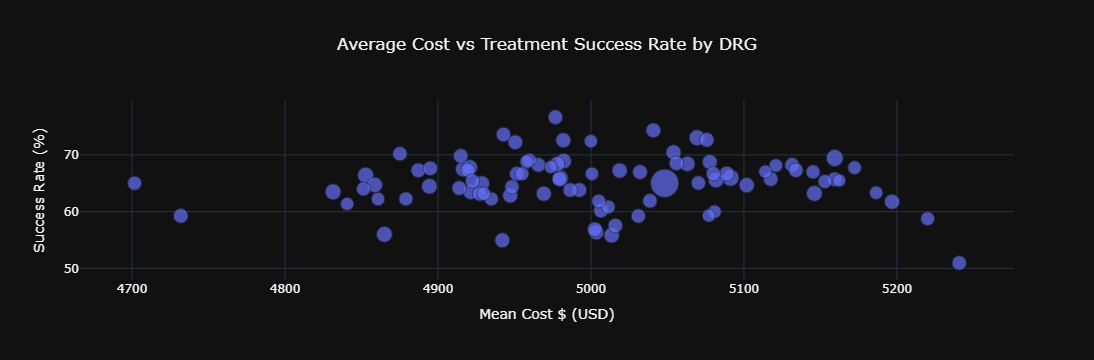

In [80]:
fig = px.scatter(
    drg_filtered,
    x = 'Mean_Cost', y = 'Success_Rate', size ='Record_Count',
    hover_name = 'DRG', title = 'Average Cost vs Treatment Success Rate by DRG'
)
fig.update_layout(
    template = 'plotly_dark', title_x = 0.5, xaxis_title = 'Mean Cost $ (USD)', yaxis_title = 'Success Rate (%)'
)
fig.show()

In [81]:
top_drg_cost = drg_filtered.sort_values('Mean_Cost', ascending = False
)
display(top_drg_cost.head(5).round(2)) 

,DRG,Record_Count,Mean_Cost,Median_Cost,Success_Rate
20,30,104,5240.75,5143.54,50.96
30,40,97,5220.09,5152.98,58.76
13,23,115,5196.83,5152.98,61.74
23,33,90,5186.46,5152.98,63.33
85,95,93,5172.31,5152.98,67.74


# we could not say anything yet!

# Logistic Regression
### target = Treatment_Success

### Features = Severity_Score / Resource_Allocated_USD / DRG / STAT 

In [82]:
model_df = df[
    ['Severity_Score', 'Resource_Allocated_USD','DRG', 'STAT', 'Treatment_Success'] 
].copy()

print("Initial Shape:", model_df.shape)

print("\nMissing Values:")
display(model_df.isnull().sum())

print("\nTarget Distribution:")
display(model_df['Treatment_Success'].value_counts())

Initial Shape: (9920, 5)

Missing Values:


Severity_Score            0
Resource_Allocated_USD    0
DRG                       0
STAT                      0
Treatment_Success         0
dtype: int64


Target Distribution:


Treatment_Success
1    6474
0    3446
Name: count, dtype: int64

In [83]:
# records of each patients
patient_counts = df.groupby('Patient_ID').size()

print("Patients with multiple records:",
      (patient_counts > 1).sum())

# common null value in DRG & STAT
print(
    "DRG and STAT Null Together:",
    (df['DRG'].isna() & df['STAT'].isna()).sum()
)

print("Duplicate Rows:", df.duplicated().sum())

Patients with multiple records: 2533
DRG and STAT Null Together: 0
Duplicate Rows: 0


In [84]:
# patient_counts = df.groupby('Patient_ID').size() 
(patient_counts > 10).value_counts() 

False    2885
True        3
Name: count, dtype: int64

In [85]:
from sklearn.model_selection import GroupShuffleSplit

model_df = df.drop_duplicates().copy()

# independent variables
X = model_df[
    [
        'Severity_Score','Resource_Allocated_USD','DRG','STAT'
    ]
]
# target variable (dependent) 
y = model_df['Treatment_Success']

groups = model_df['Patient_ID']

# 80% train  / 20% test                                             train test split
gss = GroupShuffleSplit(
    n_splits = 1,
    test_size = 0.2,
    random_state = 42
)

train_idx, test_idx = next(
    gss.split(X, y, groups = groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Train Shape:", X_train.shape)
print("Test Shape:", X_test.shape)

print("Train Patients:", groups.iloc[train_idx].nunique())
print("Test Patients:", groups.iloc[test_idx].nunique())

print(
    "Common Patients:",
    len(
        set(groups.iloc[train_idx]) &
        set(groups.iloc[test_idx])
    )
)

Train Shape: (7995, 4)
Test Shape: (1925, 4)
Train Patients: 2310
Test Patients: 578
Common Patients: 0


In [86]:
print("Train Target Distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest Target Distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))
# everything in trai test split is almost same and amazing so we can go through the model

Train Target Distribution:
Treatment_Success
1    65.74
0    34.26
Name: proportion, dtype: float64

Test Target Distribution:
Treatment_Success
1    63.27
0    36.73
Name: proportion, dtype: float64


# Model 

In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

X_train = X_train.copy()
X_test = X_test.copy()

numeric_features = [
    'Severity_Score',
    'Resource_Allocated_USD'
]

categorical_features = [
    'DRG',
    'STAT'
]

# making sure of being in categorical/object type
for col in categorical_features:
    X_train[col] = X_train[col].astype('object')
    X_test[col] = X_test[col].astype('object')

# pre-processing of numerical columns
numeric_transformer = Pipeline(steps=[    
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# pre-processing of categorical columns
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
# combining numeric and categorical columns
preprocessor = ColumnTransformer(transformers = [
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# building the model
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

# train
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [88]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score
)

#predicting
y_pred = model.predict(X_test)

# probability of success
y_prob = model.predict_proba(X_test)[:, 1]

# evaluation
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Accuracy: 0.6036

Classification Report:
              precision    recall  f1-score   support

           0       0.36      0.10      0.16       707
           1       0.63      0.90      0.74      1218

    accuracy                           0.60      1925
   macro avg       0.50      0.50      0.45      1925
weighted avg       0.53      0.60      0.53      1925


Confusion Matrix:
[[  71  636]
 [ 127 1091]]

ROC-AUC: 0.497


In [ ]:
# above result shows that logistic regression does not work well!

In [89]:
corr_df = model_df[
    [
        'Severity_Score',
        'Resource_Allocated_USD',
        'Treatment_Success'
    ]
].corr(method='spearman')

print(corr_df.round(3))

                        Severity_Score  Resource_Allocated_USD  \
Severity_Score                   1.000                   0.717   
Resource_Allocated_USD           0.717                   1.000   
Treatment_Success                0.013                   0.006   

                        Treatment_Success  
Severity_Score                      0.013  
Resource_Allocated_USD              0.006  
Treatment_Success                   1.000  


In [ ]:
# severity and cost have a good relationship with each other!
# but non of them has a good and meaningful impact on treatment success
# cost and severity have 0.738 value which is meaningful value for us.   good relation between cost & severity
# more severity, more cost 

### Probably there most be a relationship between STAT/DRG & cost or treatment success !!!!!

In [90]:
drg_success = (
    model_df.groupby('DRG')['Treatment_Success']
    .agg(['count', 'mean'])
    .reset_index()
)

drg_success['Success_Rate'] = drg_success['mean'] * 100

drg_success = drg_success[
    drg_success['count'] >= 30
]

print("Number of DRG groups:", len(drg_success))

print(
    drg_success.sort_values(
        'Success_Rate',
        ascending = False
    ).head(10)
)

Number of DRG groups: 90
   DRG  count      mean  Success_Rate
47  57    107  0.766355     76.635514
17  27    109  0.743119     74.311927
8   18    106  0.735849     73.584906
88  98    126  0.730159     73.015873
80  90    106  0.726415     72.641509
16  26    113  0.725664     72.566372
32  42     87  0.724138     72.413793
37  47    108  0.722222     72.222222
40  50    115  0.704348     70.434783
66  76    104  0.701923     70.192308


In [91]:
# bezar bashe
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    recall_score
)

def build_model(numeric_features, categorical_features):

    numeric_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    transformers = []

    if numeric_features:
        transformers.append(
            ('num', numeric_transformer, numeric_features)
        )

    if categorical_features:
        transformers.append(
            ('cat', categorical_transformer, categorical_features)
        )

    preprocessor = ColumnTransformer(transformers=transformers)

    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=2000))
    ])

    return model



experiments = {
    'Model 1 - Numeric Only': {
        'numeric': ['Severity_Score', 'Resource_Allocated_USD'],
        'categorical': []
    },

    'Model 2 - Numeric + DRG': {
        'numeric': ['Severity_Score', 'Resource_Allocated_USD'],
        'categorical': ['DRG']
    },

    'Model 3 - Numeric + DRG + STAT': {
        'numeric': ['Severity_Score', 'Resource_Allocated_USD'],
        'categorical': ['DRG', 'STAT']
    }
}

results = []

for name, features in experiments.items():

    numeric_cols = features['numeric']
    categorical_cols = features['categorical']

    selected_cols = numeric_cols + categorical_cols

    X_train_exp = X_train[selected_cols].copy()
    X_test_exp = X_test[selected_cols].copy()

    for col in categorical_cols:
        X_train_exp[col] = X_train_exp[col].astype('object')
        X_test_exp[col] = X_test_exp[col].astype('object')

    model_exp = build_model(numeric_cols, categorical_cols)

    model_exp.fit(X_train_exp, y_train)

    y_pred_exp = model_exp.predict(X_test_exp)
    y_prob_exp = model_exp.predict_proba(X_test_exp)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred_exp),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred_exp),
        'Recall Class 0': recall_score(y_test, y_pred_exp, pos_label=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob_exp)
    })


results_df = pd.DataFrame(results)

print(results_df.round(4))
# no significant difference in different scenarios

                            Model  Accuracy  Balanced Accuracy  \
0          Model 1 - Numeric Only    0.6327             0.5000   
1         Model 2 - Numeric + DRG    0.6327             0.5000   
2  Model 3 - Numeric + DRG + STAT    0.6036             0.4981   

   Recall Class 0  ROC-AUC  
0          0.0000   0.5252  
1          0.0000   0.4901  
2          0.1004   0.4970  


In [ ]:
# go to non-linear approaches like random forest

# Random Forest

In [92]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    classification_report
)
# pre-processing
numeric_features = ['Severity_Score','Resource_Allocated_USD']

categorical_features = ['DRG', 'STAT']

X_train_rf = X_train.copy()   # same train set
X_test_rf = X_test.copy()     # same test set

for col in categorical_features:
    X_train_rf[col] = X_train_rf[col].astype('object')
    X_test_rf[col] = X_test_rf[col].astype('object')


rf_preprocessor = ColumnTransformer(transformers = [
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Model
rf_model = Pipeline(steps = [ ('preprocessor', rf_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators = 400, max_depth = 10, min_samples_leaf = 10, class_weight = 'balanced', random_state = 42, n_jobs = -1
    ))
])

# train
rf_model.fit(X_train_rf, y_train)

# predict
y_pred_rf = rf_model.predict(X_test_rf)
y_prob_rf = rf_model.predict_proba(X_test_rf)[:, 1]

# evaluation
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))

print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, y_pred_rf), 4))

print("Recall Class 0:",
      round(recall_score(y_test, y_pred_rf, pos_label=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))
                                                            # also not good enough!!!! comparing logistic regression 
                                                            # neither random forest, nor logistic regression!

Accuracy: 0.5112
Balanced Accuracy: 0.5022
Recall Class 0: 0.4682
ROC-AUC: 0.4894

Classification Report:
              precision    recall  f1-score   support

           0       0.37      0.47      0.41       707
           1       0.63      0.54      0.58      1218

    accuracy                           0.51      1925
   macro avg       0.50      0.50      0.50      1925
weighted avg       0.54      0.51      0.52      1925

